In [1]:
import json
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
sns.set_theme(style="whitegrid")

CWD = Path.cwd()
BASE_DIR = CWD.parent if CWD.name == "analysis" else CWD
RESULT_DIR = BASE_DIR / "results"
FIG_DIR = RESULT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_START, TRAIN_END = "2025-02-08", "2025-11-26"
VAL_START, VAL_END     = "2025-11-27", "2026-01-01"
TEST_START, TEST_END   = "2026-01-02", "2026-02-07"

con = duckdb.connect(database=":memory:")
con.execute("PRAGMA threads=4;")

fact_cols = [
    r[0] for r in con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{(RESULT_DIR / 'fact_delay.parquet').as_posix()}')"
    ).fetchall()
]
DATE_COL = "date_id" if "date_id" in fact_cols else "date"

con.execute(f"""
CREATE OR REPLACE VIEW fact_delay AS
SELECT
    CAST({DATE_COL} AS DATE) AS date_id,
    CASE
        WHEN CAST({DATE_COL} AS DATE) BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}' THEN 'Train'
        WHEN CAST({DATE_COL} AS DATE) BETWEEN DATE '{VAL_START}'   AND DATE '{VAL_END}'   THEN 'Validation'
        WHEN CAST({DATE_COL} AS DATE) BETWEEN DATE '{TEST_START}'  AND DATE '{TEST_END}'  THEN 'Test'
    END AS period,
    * EXCLUDE ({DATE_COL})
FROM read_parquet('{(RESULT_DIR / "fact_delay.parquet").as_posix()}');

CREATE OR REPLACE VIEW dim_train AS
SELECT * FROM read_csv_auto('{(RESULT_DIR / "dim_train.csv").as_posix()}');

CREATE OR REPLACE VIEW dim_station AS
SELECT * FROM read_csv_auto('{(RESULT_DIR / "dim_station.csv").as_posix()}');
""")

print("Registered read-only views for Step 5.2 Pattern Evaluation.")

Registered read-only views for Step 5.2 Pattern Evaluation.


In [2]:
# Compute station-level arrival delay and bottleneck (>2 SD) rates separately in Train, Validation, and Test
station_period_df = con.execute("""
WITH st_period AS (
    SELECT
        f.station_name,
        s.station_full_name,
        s.station_zone,
        f.period,
        COUNT(*) AS obs_arrival_stops,
        AVG(f.delay) AS mean_arr_delay_min,
        MEDIAN(f.delay) AS median_arr_delay_min,
        AVG(CASE WHEN f.severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END) AS bottleneck_rate_pct,
        AVG(CASE WHEN f.delay <= 15.0 THEN 100.0 ELSE 0.0 END) AS on_time_15m_pct
    FROM fact_delay f
    LEFT JOIN dim_station s ON f.station_name = s.station_name
    WHERE f.is_imputed = FALSE AND f.station_no > 1
    GROUP BY 1, 2, 3, 4
)
SELECT
    station_name,
    station_full_name,
    station_zone,
    MAX(CASE WHEN period = 'Train' THEN obs_arrival_stops ELSE 0 END) AS train_stops,
    MAX(CASE WHEN period = 'Validation' THEN obs_arrival_stops ELSE 0 END) AS val_stops,
    MAX(CASE WHEN period = 'Test' THEN obs_arrival_stops ELSE 0 END) AS test_stops,
    ROUND(MAX(CASE WHEN period = 'Train' THEN mean_arr_delay_min END), 2) AS train_mean_delay,
    ROUND(MAX(CASE WHEN period = 'Validation' THEN mean_arr_delay_min END), 2) AS val_mean_delay,
    ROUND(MAX(CASE WHEN period = 'Test' THEN mean_arr_delay_min END), 2) AS test_mean_delay,
    ROUND(MAX(CASE WHEN period = 'Train' THEN bottleneck_rate_pct END), 4) AS train_bottleneck_pct,
    ROUND(MAX(CASE WHEN period = 'Validation' THEN bottleneck_rate_pct END), 4) AS val_bottleneck_pct,
    ROUND(MAX(CASE WHEN period = 'Test' THEN bottleneck_rate_pct END), 4) AS test_bottleneck_pct
FROM st_period
GROUP BY 1, 2, 3
HAVING train_stops >= 800 AND val_stops >= 80 AND test_stops >= 80
ORDER BY train_bottleneck_pct DESC;
""").df()

# Calculate cross-period Pearson & Spearman correlations across all eligible stations (and major hubs >= 15,000 train stops)
def calc_persistence_metrics(df_sub: pd.DataFrame, label: str) -> dict:
    return {
        "cohort": label,
        "n_stations": int(len(df_sub)),
        "mean_delay_pearson_train_val": round(float(df_sub["train_mean_delay"].corr(df_sub["val_mean_delay"], method="pearson")), 4),
        "mean_delay_pearson_train_test": round(float(df_sub["train_mean_delay"].corr(df_sub["test_mean_delay"], method="pearson")), 4),
        "mean_delay_spearman_train_test": round(float(df_sub["train_mean_delay"].corr(df_sub["test_mean_delay"], method="spearman")), 4),
        "bottleneck_pearson_train_val": round(float(df_sub["train_bottleneck_pct"].corr(df_sub["val_bottleneck_pct"], method="pearson")), 4),
        "bottleneck_pearson_train_test": round(float(df_sub["train_bottleneck_pct"].corr(df_sub["test_bottleneck_pct"], method="pearson")), 4),
        "bottleneck_spearman_train_test": round(float(df_sub["train_bottleneck_pct"].corr(df_sub["test_bottleneck_pct"], method="spearman")), 4),
    }

all_st_metrics = calc_persistence_metrics(station_period_df, "All_Eligible_Stations (train>=800, val>=80, test>=80)")
major_hubs_df = station_period_df[station_period_df["train_stops"] >= 15000].copy()
major_hub_metrics = calc_persistence_metrics(major_hubs_df, "Major_Transit_Hubs (train>=15,000)")

# Top-20 Hub Overlap check
top20_train_hubs = set(major_hubs_df.nlargest(20, "train_bottleneck_pct")["station_name"])
top20_val_hubs = set(major_hubs_df.nlargest(20, "val_bottleneck_pct")["station_name"])
top20_test_hubs = set(major_hubs_df.nlargest(20, "test_bottleneck_pct")["station_name"])
major_hub_metrics["top20_hub_overlap_train_vs_val"] = len(top20_train_hubs.intersection(top20_val_hubs))
major_hub_metrics["top20_hub_overlap_train_vs_test"] = len(top20_train_hubs.intersection(top20_test_hubs))

station_period_df.to_csv(RESULT_DIR / "step05_02_station_bottleneck_persistence.csv", index=False)

print("=== STATION BOTTLENECK PERSISTENCE CORRELATIONS ===")
print(pd.DataFrame([all_st_metrics, major_hub_metrics]).to_string(index=False))
print("\n=== TOP 15 MAJOR HUBS ACROSS TRAIN, VALIDATION & TEST PERIODS ===")
print(major_hubs_df.head(15).to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== STATION BOTTLENECK PERSISTENCE CORRELATIONS ===
                                               cohort  n_stations  mean_delay_pearson_train_val  mean_delay_pearson_train_test  mean_delay_spearman_train_test  bottleneck_pearson_train_val  bottleneck_pearson_train_test  bottleneck_spearman_train_test  top20_hub_overlap_train_vs_val  top20_hub_overlap_train_vs_test
All_Eligible_Stations (train>=800, val>=80, test>=80)        6896                        0.8980                         0.8618                          0.9000                        0.8366                         0.7998                          0.8092                             NaN                              NaN
                   Major_Transit_Hubs (train>=15,000)         203                        0.8668                         0.8510                          0.8381                        0.8425                         0.8660                          0.8285                            12.0                             13

In [3]:
zone_period_df = con.execute("""
SELECT
    s.station_zone,
    COUNT(*) FILTER (WHERE f.period = 'Train') AS train_stops,
    COUNT(*) FILTER (WHERE f.period = 'Validation') AS val_stops,
    COUNT(*) FILTER (WHERE f.period = 'Test') AS test_stops,
    ROUND(AVG(f.delay) FILTER (WHERE f.period = 'Train'), 2) AS train_mean_delay,
    ROUND(AVG(f.delay) FILTER (WHERE f.period = 'Validation'), 2) AS val_mean_delay,
    ROUND(AVG(f.delay) FILTER (WHERE f.period = 'Test'), 2) AS test_mean_delay,
    ROUND(AVG(CASE WHEN f.severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Train'), 4) AS train_bottleneck_pct,
    ROUND(AVG(CASE WHEN f.severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Validation'), 4) AS val_bottleneck_pct,
    ROUND(AVG(CASE WHEN f.severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Test'), 4) AS test_bottleneck_pct,
    ROUND(AVG(CASE WHEN f.delay <= 15.0 THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Train'), 2) AS train_ontime_pct,
    ROUND(AVG(CASE WHEN f.delay <= 15.0 THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Validation'), 2) AS val_ontime_pct,
    ROUND(AVG(CASE WHEN f.delay <= 15.0 THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Test'), 2) AS test_ontime_pct
FROM fact_delay f
LEFT JOIN dim_station s ON f.station_name = s.station_name
WHERE f.is_imputed = FALSE AND f.station_no > 1
GROUP BY 1
HAVING train_stops >= 10000
ORDER BY train_bottleneck_pct DESC;
""").df()

category_period_df = con.execute("""
SELECT
    t.primary_type_code,
    COUNT(*) FILTER (WHERE f.period = 'Train') AS train_stops,
    COUNT(*) FILTER (WHERE f.period = 'Validation') AS val_stops,
    COUNT(*) FILTER (WHERE f.period = 'Test') AS test_stops,
    ROUND(AVG(f.delay) FILTER (WHERE f.period = 'Train'), 2) AS train_mean_delay,
    ROUND(AVG(f.delay) FILTER (WHERE f.period = 'Validation'), 2) AS val_mean_delay,
    ROUND(AVG(f.delay) FILTER (WHERE f.period = 'Test'), 2) AS test_mean_delay,
    ROUND(AVG(CASE WHEN f.severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Train'), 4) AS train_bottleneck_pct,
    ROUND(AVG(CASE WHEN f.severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Validation'), 4) AS val_bottleneck_pct,
    ROUND(AVG(CASE WHEN f.severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Test'), 4) AS test_bottleneck_pct,
    ROUND(AVG(CASE WHEN f.delay <= 15.0 THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Train'), 2) AS train_ontime_pct,
    ROUND(AVG(CASE WHEN f.delay <= 15.0 THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Validation'), 2) AS val_ontime_pct,
    ROUND(AVG(CASE WHEN f.delay <= 15.0 THEN 100.0 ELSE 0.0 END) FILTER (WHERE f.period = 'Test'), 2) AS test_ontime_pct
FROM fact_delay f
LEFT JOIN dim_train t ON f.train_no = t.train_no
WHERE f.is_imputed = FALSE AND f.station_no > 1
GROUP BY 1
ORDER BY train_bottleneck_pct DESC;
""").df()

zone_period_df.to_csv(RESULT_DIR / "step05_02_zone_cross_period_stability.csv", index=False)
category_period_df.to_csv(RESULT_DIR / "step05_02_category_cross_period_stability.csv", index=False)

print("=== RAILWAY ZONE STABILITY ACROSS TRAIN / VALIDATION / TEST ===")
print(zone_period_df.to_string(index=False))
print("\n=== TRAIN CATEGORY STABILITY ACROSS TRAIN / VALIDATION / TEST ===")
print(category_period_df.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== RAILWAY ZONE STABILITY ACROSS TRAIN / VALIDATION / TEST ===
station_zone  train_stops  val_stops  test_stops  train_mean_delay  val_mean_delay  test_mean_delay  train_bottleneck_pct  val_bottleneck_pct  test_bottleneck_pct  train_ontime_pct  val_ontime_pct  test_ontime_pct
         SER      1150419     132784      136846             53.76           71.61            57.47                7.5315             11.4178               8.5213             47.04           39.52            42.51
        SECR       980858     120848      124554             56.90           75.17            65.88                7.4764             11.6957               8.7215             36.00           26.96            26.99
         NER      1455830     173129      175003             45.62           58.24            51.24                6.4371              8.1569               6.8125             49.75           38.63            40.64
         ECR      2867101     372221      376260             51.42           68.

In [4]:
imputation_audit_df = con.execute("""
SELECT
    period,
    CASE WHEN station_no = 1 THEN 'Origin_Departure (station_no=1)' ELSE 'EnRoute_Arrival (station_no>1)' END AS stop_context,
    is_imputed,
    has_schedule,
    COUNT(*) AS n_rows,
    ROUND(AVG(delay), 2) AS mean_delay_min,
    ROUND(MEDIAN(delay), 2) AS median_delay_min,
    ROUND(STDDEV(delay), 2) AS sd_delay_min,
    ROUND(AVG(CASE WHEN delay <= 15.0 THEN 100.0 ELSE 0.0 END), 2) AS ontime_15m_pct,
    ROUND(AVG(CASE WHEN severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END), 4) AS bottleneck_gt_2sd_pct,
    ROUND(AVG(CASE WHEN severity = 'critical' THEN 100.0 ELSE 0.0 END), 4) AS critical_gt_3sd_pct
FROM fact_delay
GROUP BY 1, 2, 3, 4
ORDER BY 1, 2, 3, 4 DESC;
""").df()

imputation_audit_df.to_csv(RESULT_DIR / "step05_02_imputation_and_limitations_audit.csv", index=False)
print("=== IMPUTATION & SCHEDULE ALIGNMENT AUDIT ACROSS PERIODS ===")
print(imputation_audit_df.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== IMPUTATION & SCHEDULE ALIGNMENT AUDIT ACROSS PERIODS ===
    period                    stop_context  is_imputed  has_schedule   n_rows  mean_delay_min  median_delay_min  sd_delay_min  ontime_15m_pct  bottleneck_gt_2sd_pct  critical_gt_3sd_pct
      Test  EnRoute_Arrival (station_no>1)       False          True  3365046           41.18              21.0         67.71           41.67                 4.1912               2.0863
      Test  EnRoute_Arrival (station_no>1)       False         False    33312           33.10              14.0         56.85           52.00                 3.6113               1.3389
      Test  EnRoute_Arrival (station_no>1)        True          True    26206           43.05              15.0         78.60           50.22                 6.2467               3.2588
      Test  EnRoute_Arrival (station_no>1)        True         False    50511           38.70              17.0         66.30           47.60                 4.3396               2.0946
      Tes

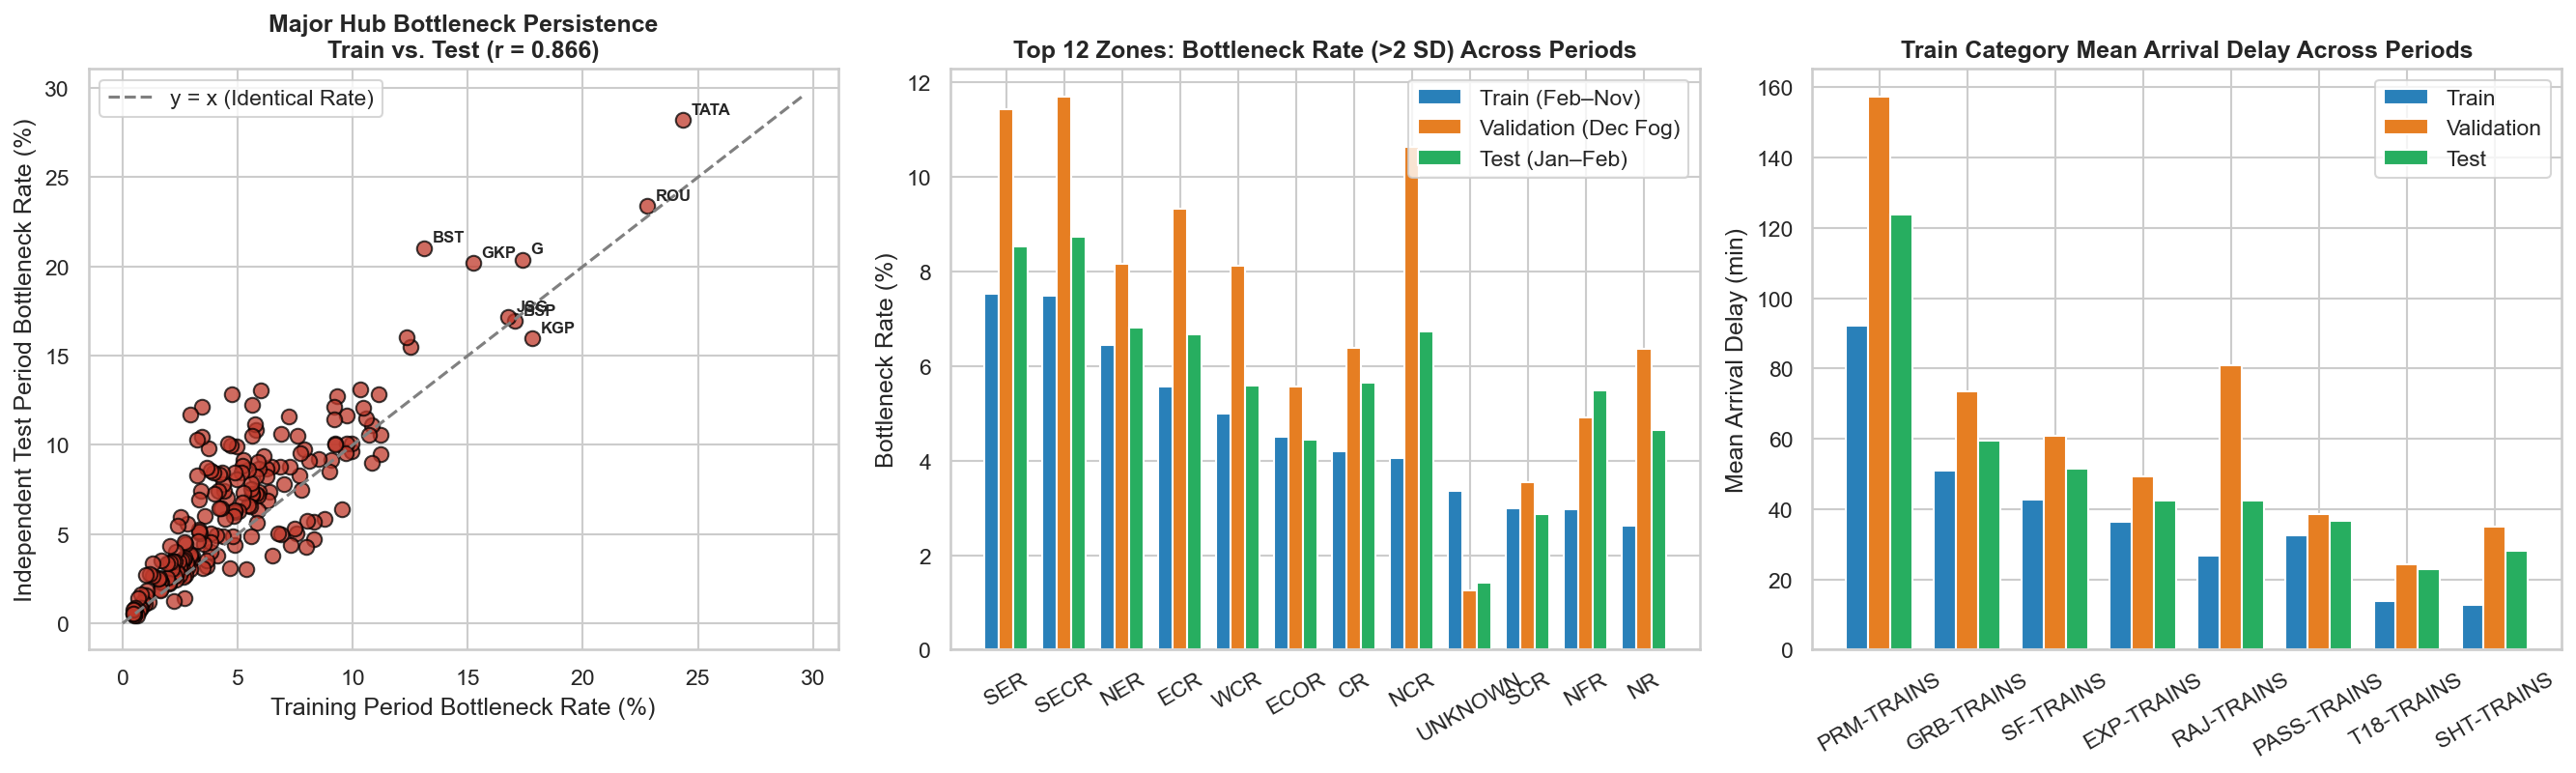

Saved Step 5.2 findings to: D:\M_Tech_CSE_AI\SEM01\DWDM\project\indian_railway_delay\results\step05_02_PATTERN_EVALUATION_FINDINGS.json


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Major Hub Bottleneck Rate Persistence (Train vs Test)
axes[0].scatter(
    major_hubs_df["train_bottleneck_pct"],
    major_hubs_df["test_bottleneck_pct"],
    color="#c0392b", alpha=0.75, edgecolor="black", s=55
)
max_b = max(major_hubs_df["train_bottleneck_pct"].max(), major_hubs_df["test_bottleneck_pct"].max()) * 1.05
axes[0].plot([0, max_b], [0, max_b], linestyle="--", color="gray", label="y = x (Identical Rate)")
for r in major_hubs_df.head(8).itertuples():
    axes[0].annotate(r.station_name, (r.train_bottleneck_pct, r.test_bottleneck_pct), xytext=(4, 3), textcoords="offset points", fontsize=8, fontweight="bold")
axes[0].set_title(f"Major Hub Bottleneck Persistence\nTrain vs. Test (r = {major_hub_metrics['bottleneck_pearson_train_test']:.3f})", fontweight="bold")
axes[0].set_xlabel("Training Period Bottleneck Rate (%)")
axes[0].set_ylabel("Independent Test Period Bottleneck Rate (%)")
axes[0].legend()

# 2. Railway Zone Bottleneck Rate Across Train, Validation & Test
z_top12 = zone_period_df.head(12)
x_z = np.arange(len(z_top12))
axes[1].bar(x_z - 0.25, z_top12["train_bottleneck_pct"], width=0.25, label="Train (Feb–Nov)", color="#2980b9")
axes[1].bar(x_z, z_top12["val_bottleneck_pct"], width=0.25, label="Validation (Dec Fog)", color="#e67e22")
axes[1].bar(x_z + 0.25, z_top12["test_bottleneck_pct"], width=0.25, label="Test (Jan–Feb)", color="#27ae60")
axes[1].set_xticks(x_z)
axes[1].set_xticklabels(z_top12["station_zone"], rotation=30)
axes[1].set_title("Top 12 Zones: Bottleneck Rate (>2 SD) Across Periods", fontweight="bold")
axes[1].set_ylabel("Bottleneck Rate (%)")
axes[1].legend()

# 3. Train Category Mean Arrival Delay Across Train, Validation & Test
x_c = np.arange(len(category_period_df))
axes[2].bar(x_c - 0.25, category_period_df["train_mean_delay"], width=0.25, label="Train", color="#2980b9")
axes[2].bar(x_c, category_period_df["val_mean_delay"], width=0.25, label="Validation", color="#e67e22")
axes[2].bar(x_c + 0.25, category_period_df["test_mean_delay"], width=0.25, label="Test", color="#27ae60")
axes[2].set_xticks(x_c)
axes[2].set_xticklabels(category_period_df["primary_type_code"], rotation=30)
axes[2].set_title("Train Category Mean Arrival Delay Across Periods", fontweight="bold")
axes[2].set_ylabel("Mean Arrival Delay (min)")
axes[2].legend()

plt.tight_layout()
fig_path = FIG_DIR / "step05_02_bottleneck_persistence_and_imputation_audit.png"
plt.savefig(fig_path, dpi=150)
plt.show()

step05_02_findings = {
    "step": "step05_02_pattern_evaluation",
    "station_bottleneck_persistence": [all_st_metrics, major_hub_metrics],
    "zone_cross_period_stability": zone_period_df.to_dict(orient="records"),
    "train_category_cross_period_stability": category_period_df.to_dict(orient="records"),
    "imputation_and_alignment_audit": imputation_audit_df.to_dict(orient="records"),
}

out_json = RESULT_DIR / "step05_02_PATTERN_EVALUATION_FINDINGS.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(step05_02_findings, f, indent=2)

print(f"Saved Step 5.2 findings to: {out_json}")